## 300m indicator - stats & vizualization for bologna

In [1]:
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import math 
import os
import sqlite3
from shapely.strtree import STRtree

TEAL  = "#1D9E75"
BLUE  = "#378ADD"
CORAL = "#F0997B"
LGRAY = "#D3D1C7"
AMBER = "#EF9F27"
TEXT  = "#2C2C2A"
SGRAY = "#888780"

plt.rcParams.update({
    "font.family":        "sans-serif",
    "font.size":          11,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.linewidth":     0.6,
    "xtick.major.size":   3,
    "ytick.major.size":   3,
    "figure.dpi":         150,
    "savefig.bbox":       "tight",
    "savefig.dpi":        150,
})


In [15]:
os.chdir("/Users/terezasaskova/Library/Mobile Documents/com~apple~CloudDocs/3-30-300-index")

CRS_METRIC = 'EPSG:32632'

buildings_routed = gpd.read_file('data/300m/300_walkability_map.gpkg', driver='GPKG', layer='buildings')
parks = gpd.read_file('data/300m/300_walkability_map.gpkg', driver='GPKG', layer='parks')
results = pd.read_csv("data/300m/buildings_300m_indicator.csv")
parks_full = pd.concat([
    gpd.read_file('data/300m/bologna_greenery.gpkg', layer=l)
    for l in ['pe_unis_all', 'osm_public']
], ignore_index=True)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver GPKG does not support open option DRIVER
  return ogr_read(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver GPKG does not support open option DRIVER
  return ogr_read(


## Stats from walkability computation mapping in Bologna

In [16]:
total    = len(results)
avg = results['walk_dist_m'].mean()
within   = results['within_300m'].sum()
no_park  = results['nearest_park_id'].isna().sum()
routed   = results['nearest_park_id'].notna().sum()
outside  = routed - within        

print('300m PARK ACCESS INDICATOR — BOLOGNA')
print(f'STREET NUMBERS:')
print(f'Total civici:                  {total:>8,}')
print(f'Within 300m walk of park:      {within:>8,}  ({within/total*100:.1f}%)')
print(f'Outside 300m (park too far):   {outside:>8,}  ({outside/total*100:.1f}%)')
print(f'No park reachable (NaN):       {no_park:>8,}  ({no_park/total*100:.1f}%)')

print(f'\nWALK DISTANCE (routed buildings only):')
reachable = results[results['nearest_park_id'].notna()]
print(f'Median walk distance:          {results["walk_dist_m"].median():>8.0f} m')
print(f'Mean walk distance:            {results["walk_dist_m"].mean():>8.0f} m')
print(f'Max walk distance:             {results["walk_dist_m"].max():>8.0f} m')

print(f'\nPARKS REACHED:')
print(f'Unique parks accessed:         {results["nearest_park_id"].nunique():>8,}')
print(f'\n  By park type:')
print(results['park_type'].value_counts(dropna=False).to_string())
print(f'\n  By park source:')
print(results['park_source'].value_counts(dropna=False).to_string())

300m PARK ACCESS INDICATOR — BOLOGNA
STREET NUMBERS:
Total civici:                    77,630
Within 300m walk of park:        56,308  (72.5%)
Outside 300m (park too far):      2,260  (2.9%)
No park reachable (NaN):         19,062  (24.6%)

WALK DISTANCE (routed buildings only):
Median walk distance:               143 m
Mean walk distance:                 152 m
Max walk distance:                 3184 m

PARKS REACHED:
Unique parks accessed:            1,068

  By park type:
park_type
osm_public     51362
NaN            19062
pe_unis_all     7206

  By park source:
park_source
OSM     51362
NaN     19062
DBSN     7206


## By neighbourhood

In [17]:
print('BY NEIGHBOURHOOD:')
neigh = (results.groupby('neighbourhood')
           .agg(
               total        = ('within_300m', 'count'),
               within_300m  = ('within_300m', 'sum'),
               median_dist  = ('walk_dist_m', 'median'),
           )
           .assign(pct_within = lambda x: x['within_300m'] / x['total'] * 100)
           .sort_values('pct_within')
)
print(neigh.to_string())

print('\nWORST 5 NEIGHBOURHOODS (by % within 300m):')
print(neigh.head())

print('\nBEST 5 NEIGHBOURHOODS:')
print(neigh.tail())

# Flag the routing outliers
print(f'\nBuildings with walk_dist > 1000m: {(results["walk_dist_m"] > 1000).sum()}')
print(f'Buildings with walk_dist > 2000m: {(results["walk_dist_m"] > 2000).sum()}')

BY NEIGHBOURHOOD:
                         total  within_300m  median_dist  pct_within
neighbourhood                                                       
Santo Stefano            16320        11261     165.8940   69.001225
Navile                   13232         9458     138.0605   71.478235
Porto - Saragozza        17302        12525     156.1720   72.390475
Borgo Panigale - Reno    10669         7916     113.7625   74.196270
San Donato - San Vitale  12629         9477     126.5345   75.041571
Savena                    7478         5671     149.2010   75.835785

WORST 5 NEIGHBOURHOODS (by % within 300m):
                         total  within_300m  median_dist  pct_within
neighbourhood                                                       
Santo Stefano            16320        11261     165.8940   69.001225
Navile                   13232         9458     138.0605   71.478235
Porto - Saragozza        17302        12525     156.1720   72.390475
Borgo Panigale - Reno    10669         79

In [18]:
# Euclidean distance 
# Available for every row that has a matched entrance (within_300m == True).
# For fig3 we need it for all addresses; for rows without an entrance we use
# the nearest-park centroid approach — but here we only have the entrance
# coords, so we restrict the euclid comparison to matched rows only.

def haversine_m(lat1, lon1, lat2, lon2):
    R = 6_371_000
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlam = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlam / 2) ** 2
    return R * 2 * np.arcsin(np.sqrt(a))

matched = results[results["within_300m"] & results["entrance_lat"].notna()].copy()
matched["euclid_dist_m"] = haversine_m(
    matched["latitude"].values,  matched["longitude"].values,
    matched["entrance_lat"].values, matched["entrance_lon"].values,
)
matched["ratio"] = matched["walk_dist_m"] / matched["euclid_dist_m"]

## Neighbourhood compliance with 300m walk to park rule

In [19]:
total   = len(results)
avg     = results["within_300m"].mean() * 100   # ← was using walk_dist mean, should be % within
within  = results["within_300m"].sum()
no_park = results["nearest_park_id"].isna().sum()
routed  = results["nearest_park_id"].notna().sum()
outside = routed - within

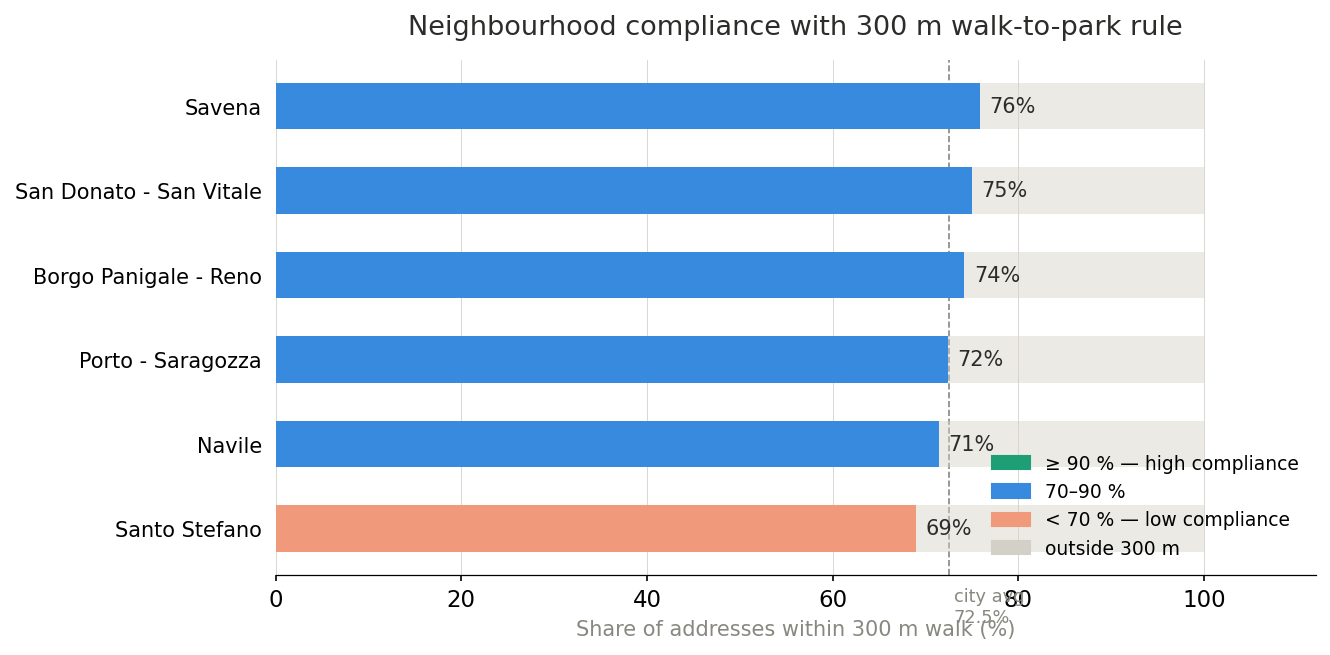

In [20]:


nb = (
    results.groupby("neighbourhood")["within_300m"]
    .agg(total="count", within="sum")
    .assign(pct=lambda x: x["within"] / x["total"] * 100)
    .sort_values("pct", ascending=True)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, max(4.5, len(nb) * 0.55)))
y     = np.arange(len(nb))
BAR_H = 0.55

colors = [TEAL if p >= 90 else BLUE if p >= 70 else CORAL for p in nb.pct]

ax.barh(y, nb.pct,       height=BAR_H, color=colors,       zorder=2)
ax.barh(y, 100 - nb.pct, height=BAR_H, left=nb.pct,
        color=LGRAY, alpha=0.45, zorder=2)

# percentage labels + checkmark — both inside the loop, correct indentation
for i, row in nb.iterrows():
    ax.text(row.pct + 1, i, f"{row.pct:.0f}%",
            va="center", fontsize=10, color=TEXT)
    if row.pct >= 99.5:
        ax.text(row.pct - 2, i, "✓",
                va="center", ha="right", fontsize=11,
                color="white", fontweight="bold")

ax.set_yticks(y)
ax.set_yticklabels(nb.neighbourhood, fontsize=10)
ax.set_xlabel("Share of addresses within 300 m walk (%)",
              fontsize=10, color=SGRAY)
ax.set_xlim(0, 112)   # single xlim — 112 gives room for the % labels

ax.set_title(
    "Neighbourhood compliance with 300 m walk-to-park rule",
    fontsize=13, fontweight="500", pad=12, color=TEXT,
)

# city average line + label at the bottom of the line
ax.axvline(avg, color=SGRAY, linewidth=0.8, linestyle="--", zorder=1)
ax.text(avg + 0.5, -0.7,
        f"city avg\n{avg:.1f}%",
        fontsize=8.5, color=SGRAY, va="top", ha="left")

ax.grid(axis="x", linewidth=0.4, color=LGRAY, zorder=0)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(left=False)

legend_els = [
    mpatches.Patch(color=TEAL,  label="≥ 90 % — high compliance"),
    mpatches.Patch(color=BLUE,  label="70–90 %"),
    mpatches.Patch(color=CORAL, label="< 70 % — low compliance"),
    mpatches.Patch(color=LGRAY, label="outside 300 m"),
]
ax.legend(
    handles=legend_els,
    loc="lower right",    # ← inside the axes, no bbox_to_anchor clipping
    fontsize=9,
    frameon=False,
)

plt.tight_layout()
plt.savefig("fig/fig01_neighborhood_walkability_compliance.png",
            dpi=150, bbox_inches="tight")
plt.show()

## Per-neighbourhood breakdown at key size of park thresholds

In [21]:
# Per-neighbourhood breakdown at key thresholds
for threshold in [0, 0.5, 1.0]:
    col = f"compliant_{threshold}ha"
    if threshold == 0:
        results[col] = results["within_300m"]
    else:
        results[col] = results["within_300m"] & (results["park_area_ha"] >= threshold)

nb_detail = results.groupby("neighbourhood").agg(
    total       = ("within_300m", "count"),
    base        = ("compliant_0ha",   "sum"),
    filter_05ha = ("compliant_0.5ha", "sum"),
    filter_1ha  = ("compliant_1.0ha", "sum"),
).assign(
    base_pct    = lambda x: x.base        / x.total * 100,
    pct_05ha    = lambda x: x.filter_05ha / x.total * 100,
    pct_1ha     = lambda x: x.filter_1ha  / x.total * 100,
    drop_05     = lambda x: x.base_pct - x.pct_05ha,
    drop_1      = lambda x: x.base_pct - x.pct_1ha,
).sort_values("base_pct", ascending=False)

print(nb_detail.round(1).to_string())

                         total   base  filter_05ha  filter_1ha  base_pct  pct_05ha  pct_1ha  drop_05  drop_1
neighbourhood                                                                                               
Savena                    7478   5671         2645        2234      75.8      35.4     29.9     40.5    46.0
San Donato - San Vitale  12629   9477         2505        1726      75.0      19.8     13.7     55.2    61.4
Borgo Panigale - Reno    10669   7916         2732        2259      74.2      25.6     21.2     48.6    53.0
Porto - Saragozza        17302  12525         3510        2232      72.4      20.3     12.9     52.1    59.5
Navile                   13232   9458         4260        2867      71.5      32.2     21.7     39.3    49.8
Santo Stefano            16320  11261         3194        2672      69.0      19.6     16.4     49.4    52.6


In [12]:
bologna_nb = ox.geocode_to_gdf("Bologna, Italy")  # city boundary

#bologna - quartieri 
quartieri = ox.features_from_place("Bologna, Italy", tags={"admin_level": "10"})
quartieri = quartieri[quartieri.geometry.geom_type.isin(["Polygon", "MultiPolygon"])]
quartieri = quartieri[["name", "geometry"]].reset_index(drop=True)
print(quartieri["name"].tolist())  

['Borgo Panigale-Reno', 'Quartiere Navile', 'San Donato-San Vitale', 'Santo Stefano', 'Porto-Saragozza', 'Savena', 'Ufficio Scuola - Quartiere Navile']


## Park access by neighbourhood: effect of size filter

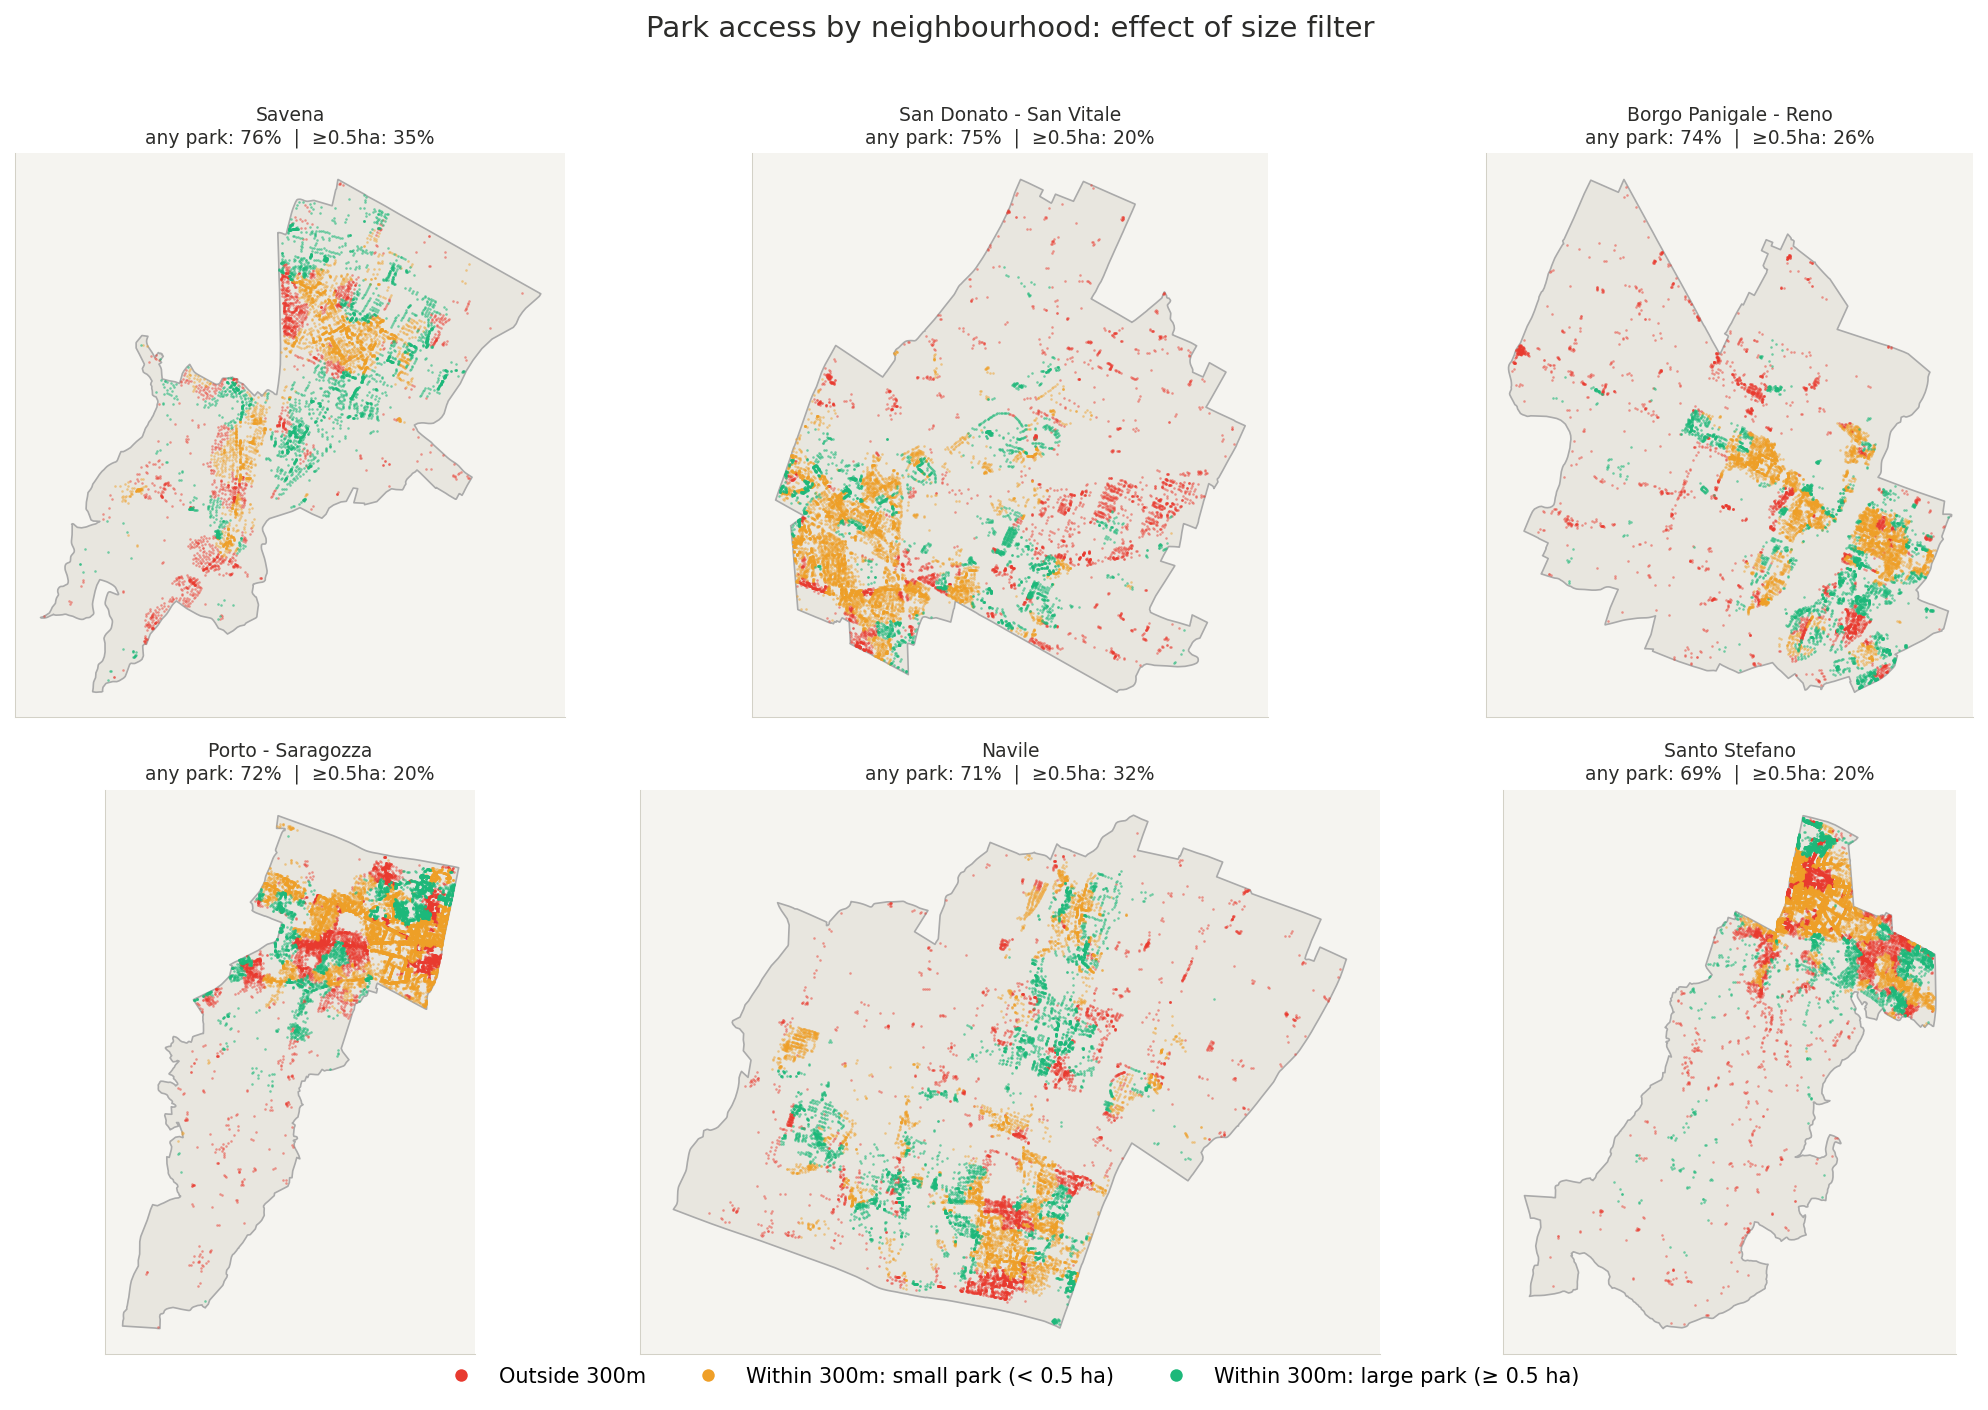

In [22]:
neighbourhoods = nb_detail.index.tolist()  # already sorted by base_pct
n_cols = 3
n_rows = math.ceil(len(neighbourhoods) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4.5))
axes = axes.flatten()

for i, nb in enumerate(neighbourhoods):
    ax = axes[i]
    nb_df = results[results["neighbourhood"] == nb]
    
    inside  = nb_df[nb_df["within_300m"]]
    outside = nb_df[~nb_df["within_300m"]]
    
    # large parks only (≥ 0.5 ha) — highlight separately
    inside_large = nb_df[nb_df["within_300m"] & (nb_df["park_area_ha"] >= 0.5)]
    inside_small = nb_df[nb_df["within_300m"] & (nb_df["park_area_ha"] <  0.5)]
    
    nb_geom = quartieri[quartieri["name"].str.contains(nb.split(" - ")[0], case=False)]
    if not nb_geom.empty:
        nb_geom.plot(ax=ax, facecolor="#E8E6DF", edgecolor="#AAAAAA",
                     linewidth=0.8, zorder=1)
    
    ax.set_facecolor("#F5F4F0")
 
    
    ax.scatter(outside["longitude"],     outside["latitude"],
        s=1.5, color="#E83A2F", alpha=0.5, linewidths=0, zorder=2, rasterized=True)
    ax.scatter(inside_small["longitude"], inside_small["latitude"],
        s=1.5, color=AMBER,     alpha=0.5, linewidths=0, zorder=3, rasterized=True)
    ax.scatter(inside_large["longitude"], inside_large["latitude"],
        s=1.5, color="#1DB87A", alpha=0.6, linewidths=0, zorder=4, rasterized=True)

    row = nb_detail.loc[nb]
    ax.set_title(
        f"{nb}\n"
        f"any park: {row.base_pct:.0f}%  |  ≥0.5ha: {row.pct_05ha:.0f}%",
        fontsize=9, color=TEXT, pad=5
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor(LGRAY)
        spine.set_linewidth(0.5)

# hide unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

# shared legend
from matplotlib.lines import Line2D
legend_els = [
    Line2D([0],[0], marker='o', color='w', markerfacecolor="#E83A2F", markersize=7, label="Outside 300m"),
    Line2D([0],[0], marker='o', color='w', markerfacecolor=AMBER,     markersize=7, label="Within 300m: small park (< 0.5 ha)"),
    Line2D([0],[0], marker='o', color='w', markerfacecolor="#1DB87A", markersize=7, label="Within 300m: large park (≥ 0.5 ha)"),
]
fig.legend(handles=legend_els, loc="lower center", ncol=3,
    fontsize=10, frameon=False, bbox_to_anchor=(0.5, -0.02))

fig.suptitle("Park access by neighbourhood: effect of size filter",
    fontsize=14, fontweight="500", color=TEXT, y=1.01)

plt.tight_layout()
plt.savefig("fig/fig02_walkability_compliance_by_neighborhood_map.png", bbox_inches="tight", dpi=180)
plt.show()

## 

In [23]:
size_df = pd.DataFrame([
    {
        "threshold": 0,
        "c_pct":  avg,
        "l_pct":  0,
        "n_pct":  never_pct,
        "parks":  df["nearest_park_id"].nunique(),
    },
    {
        "threshold": 0.5,
        "c_pct":  df["compliant_0.5ha"].mean() * 100,
        "l_pct":  avg - results["compliant_0.5ha"].mean() * 100,
        "n_pct":  never_pct,
        "parks":  results[results["park_area_ha"] >= 0.5]["nearest_park_id"].nunique(),
    },
    {
        "threshold": 1.0,
        "c_pct":  results["compliant_1.0ha"].mean() * 100,
        "l_pct":  avg - results["compliant_1.0ha"].mean() * 100,
        "n_pct":  never_pct,
        "parks":  results[results["park_area_ha"] >= 1.0]["nearest_park_id"].nunique(),
    },
])

x       = size_df.index.to_numpy()
width   = 0.6
xlabels = ["No filter", "≥ 0.5 ha", "≥ 1.0 ha"]

print(size_df)

NameError: name 'never_pct' is not defined


## Fig 2 · Park size threshold 
- sicne according to WHO park should be at least 0,5 ha 

Three address groups at each threshold:
- compliant  — within 300m of a park that meets the size requirement
- lost       — within 300m but their nearest park is smaller than threshold
- never      — never within 300m regardless of size (no park reachable)

"lost" is computed as: was within 300m at baseline, but the matched park is smaller than t ha.  It accumulates as threshold rises.

NameError: name 'x' is not defined

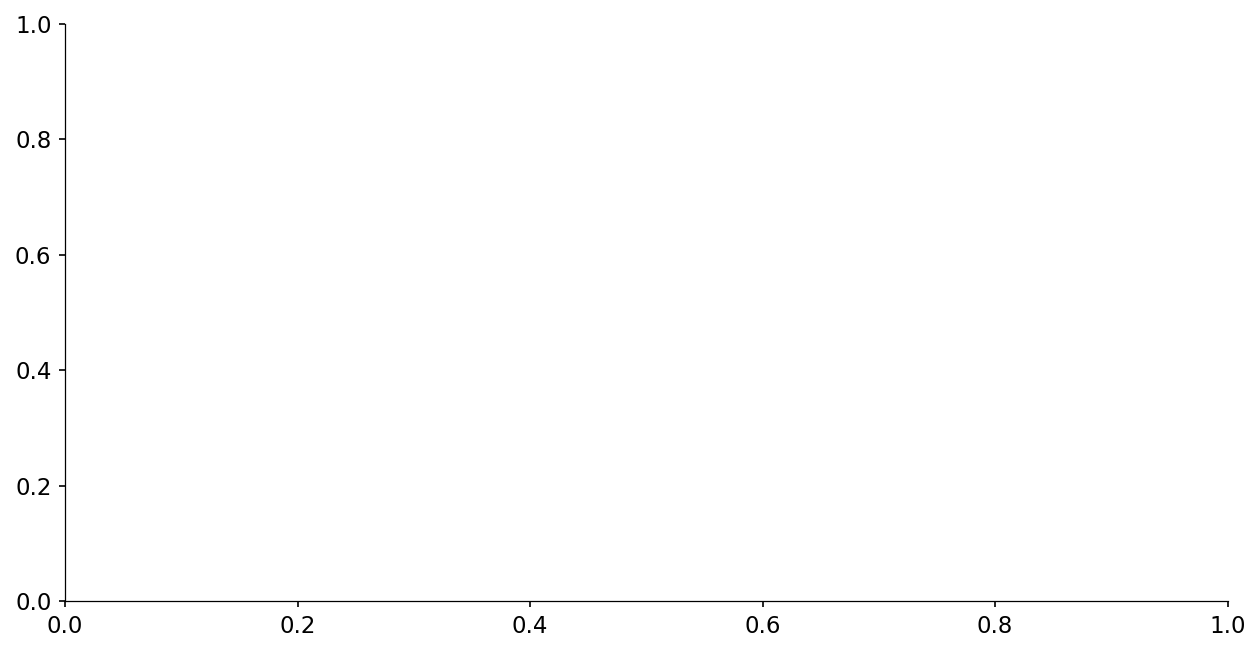

In [24]:
#Stacked compliance bars
fig, ax_top = plt.subplots(figsize=(10, 5))

b1 = ax_top.bar(x, size_df.c_pct, width, color=TEAL,  label="Compliant: park meets size threshold", zorder=2)
b2 = ax_top.bar(x, size_df.l_pct, width, bottom=size_df.c_pct, color=AMBER, label="Lost: nearest park too small", zorder=2)
b3 = ax_top.bar(x, size_df.n_pct, width, bottom=size_df.c_pct + size_df.l_pct, color=CORAL, label="Never compliant: no park within 300m", zorder=2)

for i, row in size_df.iterrows():
    if row.c_pct > 5:
        ax_top.text(i, row.c_pct / 2, f"{row.c_pct:.0f}%",
            ha="center", va="center", fontsize=9, color="white", fontweight="500")
    if row.l_pct > 3:
        ax_top.text(i, row.c_pct + row.l_pct / 2, f"{row.l_pct:.0f}%",
            ha="center", va="center", fontsize=8, color="#633806")
    if row.n_pct > 3:
        ax_top.text(i, row.c_pct + row.l_pct + row.n_pct / 2, f"{row.n_pct:.0f}%",
            ha="center", va="center", fontsize=8, color="#712B13")

ax_top.set_xticks(x)
ax_top.set_xticklabels(xlabels, fontsize=10)
ax_top.set_ylabel("Share of all addresses (%)", fontsize=10, color=SGRAY)
ax_top.set_ylim(0, 105)
ax_top.set_title("Effect of minimum park size threshold on 300m walk compliance",
    fontsize=13, fontweight="500", pad=12, color=TEXT)
ax_top.grid(axis="y", linewidth=0.4, color=LGRAY, zorder=0)
ax_top.legend(fontsize=9, frameon=False, loc="upper left",
    bbox_to_anchor=(1.01, 1.0))

plt.tight_layout()
plt.savefig("fig/fig2b_300m_by_parksize.png", bbox_inches="tight", dpi=150)
plt.show()

# ── Figure 2b: Qualifying parks ──
fig, ax_bot = plt.subplots(figsize=(10, 3.5))

ax_bot.bar(x, size_df.parks, width, color="#B5D4F4", zorder=2)
for i, row in size_df.iterrows():
    ax_bot.text(i, row.parks + size_df.parks.max() * 0.03,
        str(int(row.parks)), ha="center", va="bottom", fontsize=9, color=SGRAY)

ax_bot.set_xticks(x)
ax_bot.set_xticklabels(xlabels, fontsize=10)
ax_bot.set_ylabel("Qualifying parks", fontsize=10, color=SGRAY)
ax_bot.set_title("Number of parks surviving each size threshold",
    fontsize=13, fontweight="500", color=TEXT, pad=12)
ax_bot.set_ylim(0, size_df.parks.max() * 1.25)
ax_bot.grid(axis="y", linewidth=0.4, color=LGRAY, zorder=0)

plt.tight_layout()
plt.savefig("fig/fig03a_walkability_compliance_by_park_size.png", bbox_inches="tight", dpi=150)
plt.show()

## Fig 3 - Euclidean vs. walk compliance by threshold 
- Note: Euclidean is computed only for matched rows (entrance coords available).
- For unmatched rows, walk_dist_m is NaN → treated as non-compliant at all thresholds, which is correct.

## % of parks in: euclidean distance vs. walking distance

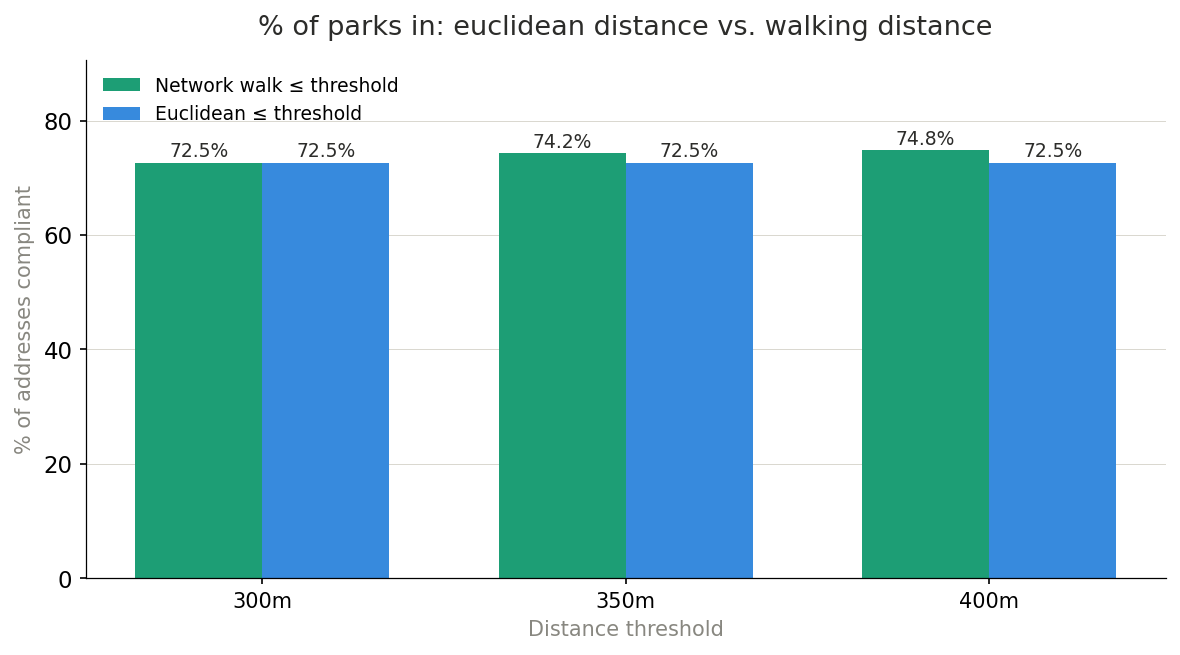

In [26]:
fig, ax = plt.subplots(figsize=(8, 4.5))

# Grouped bars, no secondary axis
b1 = ax.bar(x - w/2, walk_pct_real,   width=w, color=TEAL, label="Network walk ≤ threshold",  zorder=2, linewidth=0)
b2 = ax.bar(x + w/2, euclid_pct_real, width=w, color=BLUE, label="Euclidean ≤ threshold", zorder=2, linewidth=0)

# Value labels above bars
for bars in (b1, b2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4,
            f"{bar.get_height():.1f}%", ha="center", va="bottom", fontsize=9, color=TEXT)



ax.set_xticks(x)
ax.set_xticklabels([f"{t}m" for t in dist_thresholds], fontsize=10)
ax.set_ylabel("% of addresses compliant", fontsize=10, color=SGRAY)
ax.set_xlabel("Distance threshold", fontsize=10, color=SGRAY)
ax.set_title("% of parks in: euclidean distance vs. walking distance",
    fontsize=13, fontweight="500", pad=12, color=TEXT)
ax.set_ylim(0, max(euclid_pct_real) * 1.25)
ax.grid(axis="y", linewidth=0.4, color=LGRAY, zorder=0)

# clean single legend
ax.legend(handles=[b1, b2], fontsize=9, frameon=False,
    loc="upper left")

plt.tight_layout()
plt.savefig("fig/fig3_euclid_vs_walk.png", bbox_inches="tight", dpi=150)
plt.show()

## Fig 4  - Access gap map = address scatter coloured by 300m compliance

- Each dot = one civic address, plotted at its lon/lat.
- Teal  = within 300m walk of a park
- Coral = outside 300m (the access gap)
- Outside dots are drawn first so inside dots render on top where they overlap.

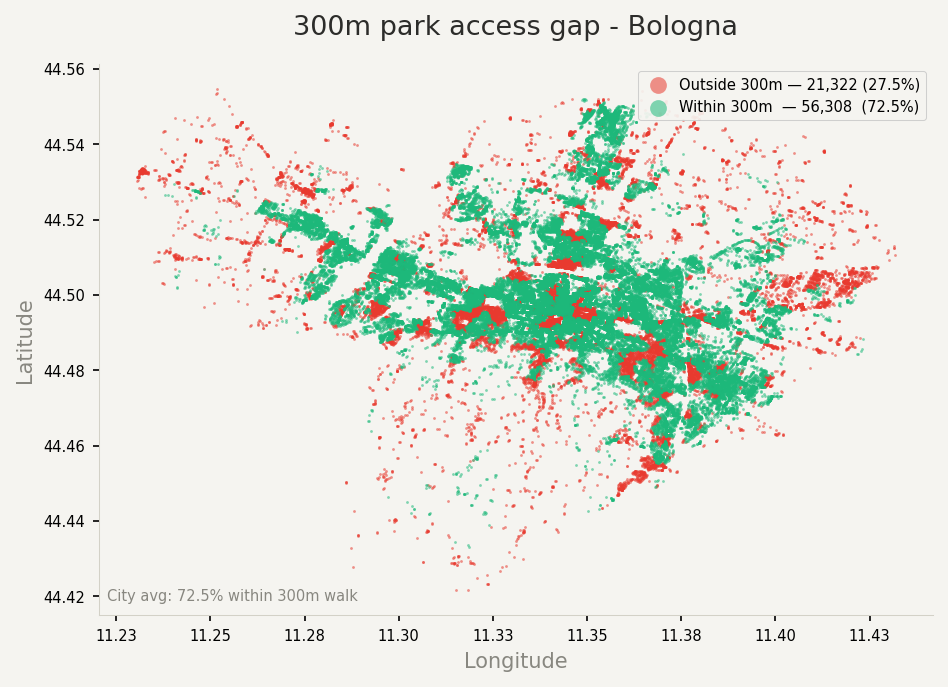

In [27]:
# Brighter colours for dot map
DOT_OUT = "#E83A2F"   # vivid red for outside (the problem)
DOT_IN  = "#1DB87A"   # vivid green for inside (the good)

inside  = results[results["within_300m"]]
outside = results[~results["within_300m"]]

lon_range = results["longitude"].max() - results["longitude"].min()
lat_range = results["latitude"].max()  - results["latitude"].min()
lat_mid   = results["latitude"].mean()
aspect    = lon_range / (lat_range * np.cos(np.radians(lat_mid)))
fig_w, fig_h = 10, 10 / aspect

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
fig.patch.set_facecolor("#F5F4F0")
ax.set_facecolor("#F5F4F0")

# Draw outside first (red), inside on top (green)
ax.scatter(outside["longitude"], outside["latitude"],
    s=1.8, color=DOT_OUT, alpha=0.55, linewidths=0,
    label=f"Outside 300m — {len(outside):,} ({len(outside)/total*100:.1f}%)",
    rasterized=True, zorder=2)
ax.scatter(inside["longitude"], inside["latitude"],
    s=1.8, color=DOT_IN,  alpha=0.55, linewidths=0,
    label=f"Within 300m  — {len(inside):,}  ({len(inside)/total*100:.1f}%)",
    rasterized=True, zorder=3)

ax.set_aspect("equal")
ax.set_xlabel("Longitude", fontsize=10, color=SGRAY)
ax.set_ylabel("Latitude",  fontsize=10, color=SGRAY)
ax.set_title("300m park access gap - Bologna",
    fontsize=13, fontweight="500", pad=14, color=TEXT)
ax.xaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))
ax.yaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))
ax.tick_params(labelsize=7)
for spine in ax.spines.values():
    spine.set_edgecolor(LGRAY)
    spine.set_linewidth(0.5)

# Legend upper right, slightly inset
legend = ax.legend(
    fontsize=7, frameon=True, framealpha=0.92, loc="upper right",
    markerscale=6, handletextpad=0.4,
)
legend.get_frame().set_linewidth(0.5)
legend.get_frame().set_facecolor("#F5F4F0")

ax.text(0.01, 0.02, f"City avg: {avg:.1f}% within 300m walk",
    transform=ax.transAxes, fontsize=7, color=SGRAY, ha="left", va="bottom")

plt.tight_layout()
plt.savefig("fig/fig4_access_gap_map.png", dpi=200, bbox_inches="tight")
plt.show()